In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import dlib

from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report,
)

from src.preprocess import preprocess_kdef_image

## 3.1 Data loading and preprocessing


In [ ]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

KDEF_TO_FER = {
    "angry": 0, "disgust": 1, "afraid": 2, "happy": 3,
    "sad": 4, "surprise": 5, "neutral": 6,
}

emotionDict = {
    0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy',
    4: 'Sad', 5: 'Surprise', 6: 'Neutral',
}
class_names = [emotionDict[i] for i in range(7)]

ROOT = Path("data/KDEF_and_AKDEF/KDEF/")

records = []
for img_path in ROOT.rglob("*.JPG"):
    stem = img_path.stem
    
    for emotion_code in EMOTIONS:
        # Frontal images only: pose code "S" (straight)
        if stem[4:] == emotion_code + "S":
            records.append({
                "path": str(img_path),
                "subject": stem[1:4],
                "emotion": EMOTIONS[emotion_code],
            })
            
            break

kdef_df = pd.DataFrame(records)
print("Frontal KDEF images:", len(kdef_df), "from", kdef_df["subject"].nunique(), "subjects")

Frontal KDEF images: 980 from 70 subjects


In [4]:
X_kdef_img, y_kdef, groups_kdef = [], [], []

for _, row in kdef_df.iterrows():
    try:
        img = preprocess_kdef_image(row["path"])
    except ValueError as e:
        print("Skipped:", e)
        continue

    X_kdef_img.append(img * 255.0)
    y_kdef.append(KDEF_TO_FER[row["emotion"]])
    groups_kdef.append(row["subject"])

X_kdef_img = np.array(X_kdef_img)
y_kdef = np.array(y_kdef)
groups_kdef = np.array(groups_kdef)

print("KDEF:", X_kdef_img.shape)

KDEF: (980, 48, 48)


## 3.2 Load test set of FER2013

In [ ]:
fer_test = pd.read_csv("./data/fer2013_test.csv")

X_fer_img = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in fer_test['pixels']])

y_fer = fer_test['emotion'].values

print("FER2013 test:", X_fer_img.shape)
print(pd.Series(y_fer).map(emotionDict).value_counts())

FER2013 test: (3589, 48, 48)
Happy       879
Neutral     626
Sad         594
Fear        528
Angry       491
Surprise    416
Disgust      55
Name: count, dtype: int64


## 3.3 Domain Shift analysis: Dataset comparison

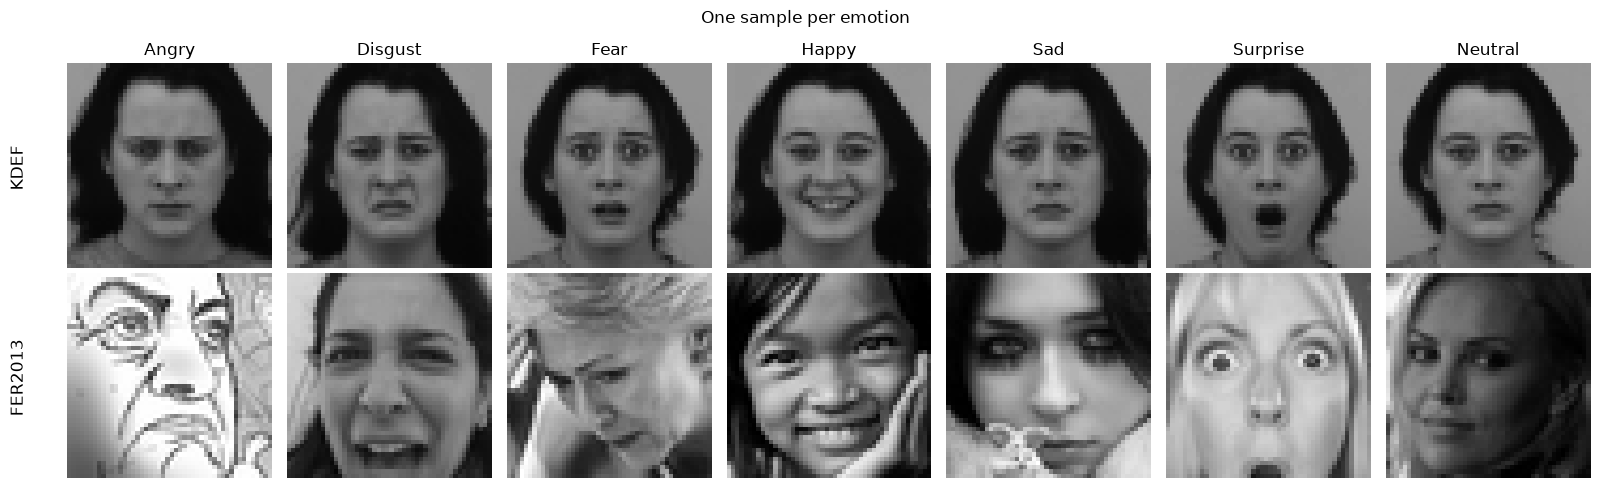

In [17]:
fig, axes = plt.subplots(2, 7, figsize=(16, 5))

INDEX = 13

for c in range(7):
    k = np.where(y_kdef == c)[0][INDEX]
    f = np.where(y_fer == c)[0][INDEX]
    
    axes[0, c].imshow(X_kdef_img[k], cmap="gray", vmin=0, vmax=255)
    axes[1, c].imshow(X_fer_img[f], cmap="gray", vmin=0, vmax=255)
    axes[0, c].set_title(emotionDict[c])
    axes[0, c].axis("off")
    axes[1, c].axis("off")

axes[0, 0].text(-10, 24, "KDEF", rotation=90, va="center", ha="right", fontsize=12)
axes[1, 0].text(-10, 24, "FER2013", rotation=90, va="center", ha="right", fontsize=12)

plt.suptitle("One sample per emotion")
plt.tight_layout()
plt.show()

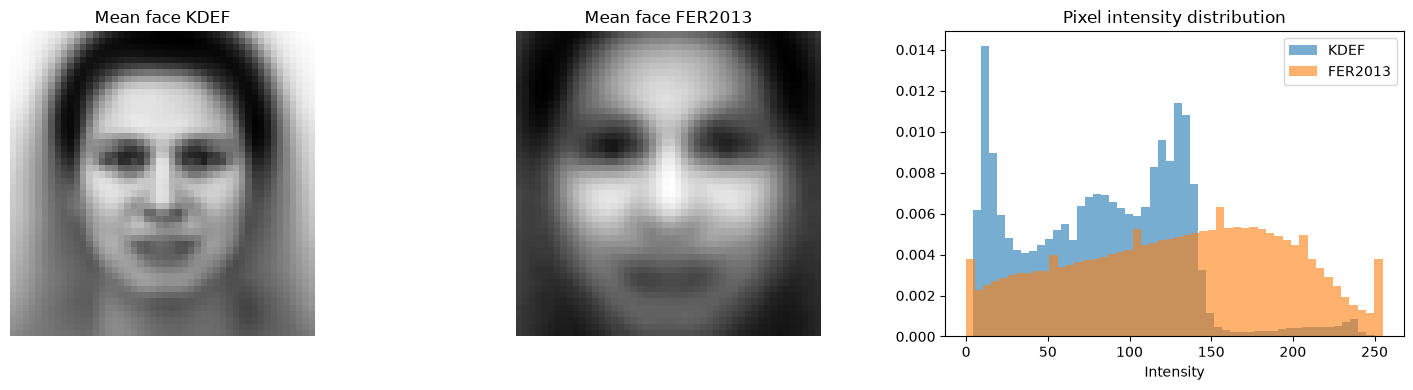

KDEF    mean 83.3  std 49.4
FER2013 mean 129.1  std 65.4


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(X_kdef_img.mean(axis=0), cmap="gray")
axes[0].set_title("Mean face KDEF")
axes[0].axis("off")

axes[1].imshow(X_fer_img.mean(axis=0), cmap="gray")
axes[1].set_title("Mean face FER2013")
axes[1].axis("off")

axes[2].hist(X_kdef_img.ravel(), bins=50, density=True, alpha=0.6, label="KDEF")
axes[2].hist(X_fer_img.ravel(), bins=50, density=True, alpha=0.6, label="FER2013")
axes[2].set_title("Pixel intensity distribution")
axes[2].set_xlabel("Intensity")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"KDEF    mean {X_kdef_img.mean():.1f}  std {X_kdef_img.std():.1f}")
print(f"FER2013 mean {X_fer_img.mean():.1f}  std {X_fer_img.std():.1f}")